In [1]:
!git clone https://github.com/pdnivedh/bigdata_capstone.git
%cd bigdata_capstone
!git checkout member1-data-lsh
!ls

Cloning into 'bigdata_capstone'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 52 (delta 13), reused 45 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (52/52), 1.25 MiB | 18.28 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/bigdata_capstone
Already on 'member1-data-lsh'
Your branch is up to date with 'origin/member1-data-lsh'.
birank_tuning_results.csv  data  README.md  requirements.txt  src


In [2]:
!pip install -r requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.5/455.5 MB 28.4 MB/s  0:00:15
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyspark: filename=pyspark-4.1.3-py2.py3-none-any.whl size=456197358 sha256=49b93287d423894f1da394a47d0c451bdae8241b28a97b1021a50280813e4c7a
  Stored in directory: /root/.cache/pip/wheels/09/f5/a7/fafe5868d8fb646b59d1a8edd38e3357f164866077917913c5
Successfully built pyspark
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.5
    Uninstalling pyspark-4.0.5:
      Successfully uninstalled pyspark-4.0.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 4.1.3 which is incompatible.


In [3]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -o "/content/drive/MyDrive/processed.zip" -d data/
!ls data/processed

Mounted at /content/drive
unzip:  cannot find or open /content/drive/MyDrive/processed.zip, /content/drive/MyDrive/processed.zip.zip or /content/drive/MyDrive/processed.zip.ZIP.
member1_candidates_top100	     member2_birank_ranked_top20.parquet
member2_birank_ranked.parquet	     ratings_test
member2_birank_ranked_settings.json  ratings_train


In [4]:
import pandas as pd

train = pd.read_parquet("data/processed/ratings_train")
test  = pd.read_parquet("data/processed/ratings_test")
cand  = pd.read_parquet("data/processed/member1_candidates_top100")
bir   = pd.read_parquet("data/processed/member2_birank_ranked.parquet")

print("train:", train.shape, list(train.columns))
print("test: ", test.shape, list(test.columns))
print("cand: ", cand.shape, list(cand.columns))
print("birank:", bir.shape, list(bir.columns))

# 1. users in the test set (expect 610)
print("\nTest users:", test["user_id"].nunique())

# 2. train/test overlap (expect 0)
overlap = train.merge(test, on=["user_id", "item_id"])
print("Train/test overlapping pairs:", len(overlap))

# 3. candidates per user (expect 100 for every user)
counts = cand.groupby("user_id").size()
print("Candidate users:", len(counts), "| min/max per user:", counts.min(), counts.max())

# 4. test items not in the training graph (cannot be recommended)
train_items = set(train["item_id"])
not_in_graph = ~test["item_id"].isin(train_items)
print(f"\nTest rows with item not in train graph: {not_in_graph.mean():.2%}")
liked = test[test["rating"] >= 4.0]
print(f"Same, among liked test rows (rating >= 4): {(~liked['item_id'].isin(train_items)).mean():.2%}")

train: (80419, 4) ['item_id', 'user_id', 'rating', 'timestamp']
test:  (20417, 4) ['item_id', 'user_id', 'rating', 'timestamp']
cand:  (61000, 5) ['user_id', 'item_id', 'similarity', 'rank', 'candidate_source']
birank: (61000, 8) ['user_id', 'item_id', 'similarity', 'lsh_rank', 'candidate_source', 'birank_score', 'birank_used', 'rank']

Test users: 610
Train/test overlapping pairs: 0
Candidate users: 610 | min/max per user: 100 100

Test rows with item not in train graph: 8.34%
Same, among liked test rows (rating >= 4): 6.59%


In [5]:
import numpy as np
import pandas as pd

def evaluate(ranked, test, k=10, like_threshold=4.0, valid_items=None):
    """ranked: DataFrame[user_id, item_id, rank]; test: DataFrame[user_id, item_id, rating].
    valid_items: if given, only these items count as relevant (graph-only version)."""
    t = test[test["rating"] >= like_threshold]
    if valid_items is not None:
        t = t[t["item_id"].isin(valid_items)]
    rel = t.groupby("user_id")["item_id"].apply(set)
    rows = []
    top = ranked[ranked["rank"] <= k].sort_values(["user_id", "rank"])
    for u, items in top.groupby("user_id")["item_id"]:
        truth = rel.get(u, set())
        if not truth:
            continue
        hits = [i in truth for i in items]
        dcg = sum(h / np.log2(p + 2) for p, h in enumerate(hits))
        idcg = sum(1 / np.log2(p + 2) for p in range(min(len(truth), k)))
        rows.append({"user_id": u, "precision": sum(hits) / k, "recall": sum(hits) / len(truth),
                     "ndcg": dcg / idcg, "hit": float(any(hits))})
    return pd.DataFrame(rows)

# The two orderings of the SAME 100 candidates
lsh_order    = bir[["user_id", "item_id", "lsh_rank"]].rename(columns={"lsh_rank": "rank"})
birank_order = bir[["user_id", "item_id", "rank"]]

settings = {"strict": None, "graph_only": train_items}
per_user = {}   # keep per-user results for the significance test later
summary = []

for setting, valid in settings.items():
    for k in (10, 20):
        for name, order in [("LSH order", lsh_order), ("LSH + BiRank", birank_order)]:
            res = evaluate(order, test, k=k, valid_items=valid)
            per_user[(name, setting, k)] = res
            summary.append({"setting": setting, "K": k, "method": name, "users": len(res),
                            "precision": res["precision"].mean(), "recall": res["recall"].mean(),
                            "ndcg": res["ndcg"].mean(), "hit": res["hit"].mean()})

pd.DataFrame(summary).round(4)

,setting,K,method,users,precision,recall,ndcg,hit
0,strict,10,LSH order,592,0.0103,0.0107,0.0135,0.0946
1,strict,10,LSH + BiRank,592,0.0392,0.0357,0.0557,0.2855
2,strict,20,LSH order,592,0.0094,0.0171,0.0160,0.1571
3,strict,20,LSH + BiRank,592,0.0259,0.0445,0.0525,0.3378
4,graph_only,10,LSH order,591,0.0103,0.0109,0.0136,0.0948
5,graph_only,10,LSH + BiRank,591,0.0393,0.0362,0.0560,0.2860
6,graph_only,20,LSH order,591,0.0094,0.0176,0.0162,0.1574
7,graph_only,20,LSH + BiRank,591,0.0260,0.0453,0.0528,0.3384


In [7]:
pop = train.groupby("item_id").size().sort_values(ascending=False)
seen = train.groupby("user_id")["item_id"].apply(set)
users = bir["user_id"].unique()

# (1) FULL CATALOG: most popular unseen movies, top 100 per user
rows = []
for u in users:
    s = seen.get(u, set())
    recs = [i for i in pop.index if i not in s][:100]
    rows += [(u, i, r + 1) for r, i in enumerate(recs)]
pop_full = pd.DataFrame(rows, columns=["user_id", "item_id", "rank"])

# (2) SAME CANDIDATES: reorder the 100 LSH candidates by popularity
pop_cand = bir[["user_id", "item_id", "lsh_rank"]].copy()
pop_cand["pop"] = pop_cand["item_id"].map(pop).fillna(0)
pop_cand = pop_cand.sort_values(["user_id", "pop", "lsh_rank"], ascending=[True, False, True])
pop_cand["rank"] = pop_cand.groupby("user_id").cumcount() + 1

orders = {}
orders["Popularity (same candidates)"] = pop_cand
orders["Popularity (full catalog)"] = pop_full

for setting, valid in settings.items():
    for k in (10, 20):
        for name, order in orders.items():
            res = evaluate(order, test, k=k, valid_items=valid)
            per_user[(name, setting, k)] = res
            summary.append({"setting": setting, "K": k, "method": name, "users": len(res),
                            "precision": res["precision"].mean(), "recall": res["recall"].mean(),
                            "ndcg": res["ndcg"].mean(), "hit": res["hit"].mean()})

pd.DataFrame(summary).round(4).sort_values(["setting", "K", "method"]).reset_index(drop=True)

,setting,K,method,users,precision,recall,ndcg,hit
0,graph_only,10,LSH + BiRank,591,0.0393,0.0362,0.0560,0.2860
1,graph_only,10,LSH order,591,0.0103,0.0109,0.0136,0.0948
2,graph_only,10,Popularity (full catalog),591,0.0579,0.0497,0.0756,0.3232
3,graph_only,10,Popularity (same candidates),591,0.0296,0.0277,0.0417,0.2234
4,graph_only,20,LSH + BiRank,591,0.0260,0.0453,0.0528,0.3384
5,graph_only,20,LSH order,591,0.0094,0.0176,0.0162,0.1574
6,graph_only,20,Popularity (full catalog),591,0.0486,0.0840,0.0818,0.4315
7,graph_only,20,Popularity (same candidates),591,0.0210,0.0359,0.0402,0.2792
8,strict,10,LSH + BiRank,592,0.0392,0.0357,0.0557,0.2855
9,strict,10,LSH order,592,0.0103,0.0107,0.0135,0.0946


In [8]:
import time
import numpy as np
import scipy.sparse as sp

t0 = time.time()
user_ids = np.sort(train["user_id"].unique())
item_ids = np.sort(train["item_id"].unique())
u_map = {u: i for i, u in enumerate(user_ids)}
i_map = {m: j for j, m in enumerate(item_ids)}

R = sp.csr_matrix(
    (train["rating"].astype("float32"),
     (train["user_id"].map(u_map), train["item_id"].map(i_map))),
    shape=(len(user_ids), len(item_ids)))

# item-item cosine similarity
norms = np.sqrt(R.multiply(R).sum(axis=0)).A1
Rn = R @ sp.diags(1.0 / norms)
S = (Rn.T @ Rn).toarray().astype("float32")
np.fill_diagonal(S, 0)
t_build = time.time() - t0

# score every movie for every user = sum of rating-weighted similarities
t1 = time.time()
scores = np.asarray(R @ S)
rr, cc = R.nonzero()
scores[rr, cc] = -np.inf          # never recommend already-rated movies
t_score = time.time() - t1
print(f"item-CF build: {t_build:.1f}s | scoring: {t_score:.1f}s")

# (1) FULL CATALOG: top 100 unseen per user
top = np.argsort(-scores, axis=1)[:, :100]
rows = [(user_ids[u], item_ids[j], r + 1) for u in range(len(user_ids)) for r, j in enumerate(top[u])]
cf_full = pd.DataFrame(rows, columns=["user_id", "item_id", "rank"])

# (2) SAME CANDIDATES: reorder the 100 LSH candidates by item-CF score
cf_cand = bir[["user_id", "item_id", "lsh_rank"]].copy()
cf_cand["score"] = scores[cf_cand["user_id"].map(u_map).values, cf_cand["item_id"].map(i_map).values]
cf_cand = cf_cand.sort_values(["user_id", "score", "lsh_rank"], ascending=[True, False, True])
cf_cand["rank"] = cf_cand.groupby("user_id").cumcount() + 1

orders = {"Item-CF (same candidates)": cf_cand, "Item-CF (full catalog)": cf_full}
for setting, valid in settings.items():
    for k in (10, 20):
        for name, order in orders.items():
            res = evaluate(order, test, k=k, valid_items=valid)
            per_user[(name, setting, k)] = res
            summary.append({"setting": setting, "K": k, "method": name, "users": len(res),
                            "precision": res["precision"].mean(), "recall": res["recall"].mean(),
                            "ndcg": res["ndcg"].mean(), "hit": res["hit"].mean()})

pd.DataFrame(summary).round(4).sort_values(["setting", "K", "method"]).reset_index(drop=True)

item-CF build: 1.0s | scoring: 0.6s


,setting,K,method,users,precision,recall,ndcg,hit
0,graph_only,10,Item-CF (full catalog),591,0.0728,0.0740,0.0906,0.4281
1,graph_only,10,Item-CF (same candidates),591,0.0340,0.0339,0.0496,0.2572
2,graph_only,10,LSH + BiRank,591,0.0393,0.0362,0.0560,0.2860
3,graph_only,10,LSH order,591,0.0103,0.0109,0.0136,0.0948
4,graph_only,10,Popularity (full catalog),591,0.0579,0.0497,0.0756,0.3232
5,graph_only,10,Popularity (same candidates),591,0.0296,0.0277,0.0417,0.2234
6,graph_only,20,Item-CF (full catalog),591,0.0609,0.1258,0.1036,0.5516
7,graph_only,20,Item-CF (same candidates),591,0.0239,0.0442,0.0491,0.3249
8,graph_only,20,LSH + BiRank,591,0.0260,0.0453,0.0528,0.3384
9,graph_only,20,LSH order,591,0.0094,0.0176,0.0162,0.1574


In [10]:
import os, glob
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null

# use whichever Java 17 folder actually exists
java_dirs = glob.glob("/usr/lib/jvm/*17*")
print("Java found at:", java_dirs)
os.environ["JAVA_HOME"] = java_dirs[0]
!$JAVA_HOME/bin/java -version

from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local[*]").appName("als") \
    .config("spark.driver.memory", "4g").config("spark.ui.enabled", "false").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Java found at: ['/usr/lib/jvm/java-17-openjdk-amd64', '/usr/lib/jvm/java-1.17.0-openjdk-amd64']
openjdk version "17.0.21.1" 2026-11-17
OpenJDK Runtime Environment (build 17.0.21.1+2-1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.21.1+2-1-24.04.1-Ubuntu, mixed mode, sharing)
Spark 4.1.3


In [12]:
from pyspark import SparkContext
from pyspark.sql import SparkSession

try:
    spark.stop()
except Exception:
    pass
SparkContext._gateway = None
SparkContext._jvm = None
SparkContext._active_spark_context = None
SparkSession._instantiatedSession = None

spark = (SparkSession.builder.master("local[4]").appName("als")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.default.parallelism", "8")
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir("/content/ckpt")
print("Spark", spark.version)

Spark 4.1.3


In [13]:
import itertools, time
from pyspark.ml.recommendation import ALS

# last 20% of each user's TRAIN history (by time) = validation
tr = train.sort_values(["user_id", "timestamp"]).copy()
pos = tr.groupby("user_id").cumcount()
n = tr.groupby("user_id")["item_id"].transform("size")
is_val = pos >= (0.8 * n).astype(int)
sub_train, val = tr[~is_val], tr[is_val]
print("sub-train:", len(sub_train), "| validation:", len(val))

sub_sdf = spark.createDataFrame(
    sub_train[["user_id", "item_id", "rating"]].astype({"user_id": "int", "item_id": "int", "rating": "float"})
).coalesce(4).cache()
sub_sdf.count()

def als_scores(sdf, rank, reg, iters, alpha=10.0):
    model = ALS(userCol="user_id", itemCol="item_id", ratingCol="rating", implicitPrefs=True,
                rank=rank, regParam=reg, maxIter=iters, alpha=alpha,
                numUserBlocks=4, numItemBlocks=4, checkpointInterval=5,
                coldStartStrategy="drop", seed=42).fit(sdf)
    U, V = model.userFactors.toPandas(), model.itemFactors.toPandas()
    Um, Vm = np.vstack(U["features"].values), np.vstack(V["features"].values)
    return U["id"].values, V["id"].values, Um @ Vm.T

val_liked = val[val["rating"] >= 4.0].groupby("user_id")["item_id"].apply(set)

def val_recall(uid, iid, S, seen_df, k=100):
    u_idx = {u: i for i, u in enumerate(uid)}
    i_idx = {m: j for j, m in enumerate(iid)}
    S = S.copy()
    r, c = seen_df["user_id"].map(u_idx), seen_df["item_id"].map(i_idx)
    ok = r.notna() & c.notna()
    S[r[ok].astype(int).values, c[ok].astype(int).values] = -np.inf   # drop already-rated
    top = np.argsort(-S, axis=1)[:, :k]
    rec = [len(set(iid[top[u_idx[u]]]) & truth) / len(truth)
           for u, truth in val_liked.items() if u in u_idx]
    return float(np.mean(rec))

results = []
for rank, reg, iters in itertools.product([10, 30, 50], [0.01, 0.1], [10, 20]):
    t0 = time.time()
    uid, iid, S = als_scores(sub_sdf, rank, reg, iters)
    results.append({"rank": rank, "regParam": reg, "maxIter": iters,
                    "val_recall@100": round(val_recall(uid, iid, S, sub_train), 4),
                    "fit_s": round(time.time() - t0, 1)})
    print(results[-1])

pd.DataFrame(results).sort_values("val_recall@100", ascending=False).reset_index(drop=True)

sub-train: 64081 | validation: 16338
{'rank': 10, 'regParam': 0.01, 'maxIter': 10, 'val_recall@100': 0.3789, 'fit_s': 18.9}
{'rank': 10, 'regParam': 0.01, 'maxIter': 20, 'val_recall@100': 0.3846, 'fit_s': 16.3}
{'rank': 10, 'regParam': 0.1, 'maxIter': 10, 'val_recall@100': 0.383, 'fit_s': 9.3}
{'rank': 10, 'regParam': 0.1, 'maxIter': 20, 'val_recall@100': 0.3853, 'fit_s': 13.5}
{'rank': 30, 'regParam': 0.01, 'maxIter': 10, 'val_recall@100': 0.3974, 'fit_s': 7.2}
{'rank': 30, 'regParam': 0.01, 'maxIter': 20, 'val_recall@100': 0.4038, 'fit_s': 14.4}
{'rank': 30, 'regParam': 0.1, 'maxIter': 10, 'val_recall@100': 0.4066, 'fit_s': 8.5}
{'rank': 30, 'regParam': 0.1, 'maxIter': 20, 'val_recall@100': 0.4097, 'fit_s': 12.0}
{'rank': 50, 'regParam': 0.01, 'maxIter': 10, 'val_recall@100': 0.4006, 'fit_s': 9.8}
{'rank': 50, 'regParam': 0.01, 'maxIter': 20, 'val_recall@100': 0.3976, 'fit_s': 17.9}
{'rank': 50, 'regParam': 0.1, 'maxIter': 10, 'val_recall@100': 0.4046, 'fit_s': 10.9}
{'rank': 50, 're

,rank,regParam,maxIter,val_recall@100,fit_s
0,30,0.10,20,0.4097,12.0
1,30,0.10,10,0.4066,8.5
2,50,0.10,10,0.4046,10.9
3,30,0.01,20,0.4038,14.4
4,50,0.01,10,0.4006,9.8
5,50,0.10,20,0.4002,17.3
6,50,0.01,20,0.3976,17.9
7,30,0.01,10,0.3974,7.2
8,10,0.10,20,0.3853,13.5
9,10,0.01,20,0.3846,16.3


In [14]:
t0 = time.time()
full_sdf = spark.createDataFrame(
    train[["user_id", "item_id", "rating"]].astype({"user_id": "int", "item_id": "int", "rating": "float"})
).coalesce(4).cache()
full_sdf.count()

uid, iid, S = als_scores(full_sdf, 30, 0.1, 20)      # frozen: rank=30, regParam=0.1, maxIter=20
t_als = time.time() - t0
print(f"ALS final training (all of ratings_train): {t_als:.1f}s | users: {len(uid)} | items: {len(iid)}")

runtimes = {"Item-CF build + scoring (s)": round(t_build + t_score, 1),
            "ALS final training (s)": round(t_als, 1)}

u_idx = {u: i for i, u in enumerate(uid)}
i_idx = {m: j for j, m in enumerate(iid)}

# (1) FULL CATALOG: top 100 unseen movies per user
S_full = S.copy()
rr = train["user_id"].map(u_idx)
cc = train["item_id"].map(i_idx)
ok = rr.notna() & cc.notna()
S_full[rr[ok].astype(int).values, cc[ok].astype(int).values] = -np.inf
top = np.argsort(-S_full, axis=1)[:, :100]
rows = [(uid[a], iid[b], pos + 1) for a in range(len(uid)) for pos, b in enumerate(top[a])]
als_full = pd.DataFrame(rows, columns=["user_id", "item_id", "rank"])

# (2) SAME CANDIDATES: reorder the 100 LSH candidates by ALS score
cu = bir["user_id"].map(u_idx)
ci = bir["item_id"].map(i_idx)
m = (cu.notna() & ci.notna()).values
sc = np.full(len(bir), -np.inf)
sc[m] = S[cu[m].astype(int).values, ci[m].astype(int).values]
als_cand = bir[["user_id", "item_id", "lsh_rank"]].copy()
als_cand["score"] = sc
als_cand = als_cand.sort_values(["user_id", "score", "lsh_rank"], ascending=[True, False, True])
als_cand["rank"] = als_cand.groupby("user_id").cumcount() + 1

orders = {"ALS (same candidates)": als_cand, "ALS (full catalog)": als_full}
for setting, valid in settings.items():
    for k in (10, 20):
        for name, order in orders.items():
            res = evaluate(order, test, k=k, valid_items=valid)
            per_user[(name, setting, k)] = res
            summary.append({"setting": setting, "K": k, "method": name, "users": len(res),
                            "precision": res["precision"].mean(), "recall": res["recall"].mean(),
                            "ndcg": res["ndcg"].mean(), "hit": res["hit"].mean()})

out = pd.DataFrame(summary)
out = out[out["setting"] == "strict"].sort_values(["K", "ndcg"], ascending=[True, False])
out.round(4).reset_index(drop=True)

ALS final training (all of ratings_train): 21.5s | users: 610 | items: 8230


,setting,K,method,users,precision,recall,ndcg,hit
0,strict,10,Item-CF (full catalog),592,0.0726,0.0730,0.0901,0.4274
1,strict,10,Popularity (full catalog),592,0.0578,0.0487,0.0753,0.3226
2,strict,10,ALS (full catalog),592,0.0544,0.0692,0.0713,0.3666
3,strict,10,LSH + BiRank,592,0.0392,0.0357,0.0557,0.2855
4,strict,10,Item-CF (same candidates),592,0.0340,0.0333,0.0493,0.2568
5,strict,10,ALS (same candidates),592,0.0331,0.0330,0.0478,0.2568
6,strict,10,Popularity (same candidates),592,0.0296,0.0273,0.0416,0.2230
7,strict,10,LSH order,592,0.0103,0.0107,0.0135,0.0946
8,strict,20,Item-CF (full catalog),592,0.0608,0.1240,0.1029,0.5507
9,strict,20,ALS (full catalog),592,0.0514,0.1257,0.0913,0.5372


In [15]:
import os
from scipy.stats import wilcoxon

os.makedirs("results", exist_ok=True)
rng = np.random.default_rng(42)

def paired(a_name, b_name, setting="strict", k=10, metric="ndcg"):
    a = per_user[(a_name, setting, k)].set_index("user_id")[metric]
    b = per_user[(b_name, setting, k)].set_index("user_id")[metric]
    d = (a - b.reindex(a.index)).dropna()
    boots = d.values[rng.integers(0, len(d), size=(5000, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    try:
        p = wilcoxon(d).pvalue
    except ValueError:
        p = np.nan
    return {"K": k, "metric": metric, "comparison": f"{a_name} - {b_name}", "users": len(d),
            "mean_diff": d.mean(), "ci95_low": lo, "ci95_high": hi, "wilcoxon_p": p}

rows = []
for other in ["LSH order", "Popularity (same candidates)", "Item-CF (same candidates)", "ALS (same candidates)"]:
    for k in (10, 20):
        for metric in ("ndcg", "recall"):
            rows.append(paired("LSH + BiRank", other, "strict", k, metric))
sig = pd.DataFrame(rows)
print("Same candidates, strict setting. mean_diff > 0 means BiRank is better.\n")
display(sig.round(4))

# mean and bootstrap 95% CI per method (same-candidate methods, strict)
def mean_ci(name, setting="strict", k=10, metric="ndcg"):
    v = per_user[(name, setting, k)][metric].values
    boots = v[rng.integers(0, len(v), size=(5000, len(v)))].mean(axis=1)
    return {"method": name, "K": k, "metric": metric, "mean": v.mean(),
            "ci95_low": np.percentile(boots, 2.5), "ci95_high": np.percentile(boots, 97.5)}

same = ["LSH order", "Popularity (same candidates)", "Item-CF (same candidates)",
        "ALS (same candidates)", "LSH + BiRank"]
ci_table = pd.DataFrame([mean_ci(n, "strict", k, m) for n in same for k in (10, 20) for m in ("ndcg", "recall")])
display(ci_table.round(4))

# save everything
pd.DataFrame(summary).to_csv("results/summary_all_methods.csv", index=False)
sig.to_csv("results/significance_birank_vs_others.csv", index=False)
ci_table.to_csv("results/mean_ci_same_candidates.csv", index=False)
pd.concat([df.assign(method=key[0], setting=key[1], K=key[2]) for key, df in per_user.items()]
          ).to_csv("results/per_user_results.csv", index=False)
pd.DataFrame([runtimes]).to_csv("results/runtimes_partial.csv", index=False)

!zip -qr results.zip results
from google.colab import files
files.download("results.zip")

Same candidates, strict setting. mean_diff > 0 means BiRank is better.



,K,metric,comparison,users,mean_diff,ci95_low,ci95_high,wilcoxon_p
0,10,ndcg,LSH + BiRank - LSH order,592,0.0422,0.0338,0.0508,0.0000
1,10,recall,LSH + BiRank - LSH order,592,0.0250,0.0184,0.0321,0.0000
2,20,ndcg,LSH + BiRank - LSH order,592,0.0365,0.0291,0.0445,0.0000
3,20,recall,LSH + BiRank - LSH order,592,0.0274,0.0199,0.0352,0.0000
4,10,ndcg,LSH + BiRank - Popularity (same candidates),592,0.0142,0.0098,0.0190,0.0000
5,10,recall,LSH + BiRank - Popularity (same candidates),592,0.0084,0.0058,0.0113,0.0000
6,20,ndcg,LSH + BiRank - Popularity (same candidates),592,0.0126,0.0088,0.0166,0.0000
7,20,recall,LSH + BiRank - Popularity (same candidates),592,0.0092,0.0060,0.0126,0.0000
8,10,ndcg,LSH + BiRank - Item-CF (same candidates),592,0.0065,0.0025,0.0106,0.0012
9,10,recall,LSH + BiRank - Item-CF (same candidates),592,0.0024,-0.0004,0.0051,0.0135


,method,K,metric,mean,ci95_low,ci95_high
0,LSH order,10,ndcg,0.0135,0.0093,0.0181
1,LSH order,10,recall,0.0107,0.0073,0.0146
2,LSH order,20,ndcg,0.0160,0.0119,0.0207
3,LSH order,20,recall,0.0171,0.0124,0.0224
4,Popularity (same candidates),10,ndcg,0.0416,0.0342,0.0493
5,Popularity (same candidates),10,recall,0.0273,0.0209,0.0344
6,Popularity (same candidates),20,ndcg,0.0400,0.0336,0.0466
7,Popularity (same candidates),20,recall,0.0353,0.0286,0.0427
8,Item-CF (same candidates),10,ndcg,0.0493,0.0412,0.0580
9,Item-CF (same candidates),10,recall,0.0333,0.0264,0.0409


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import shutil, subprocess, time

shutil.copytree("data/processed", "/content/rt_data", dirs_exist_ok=True)

times = []
for _ in range(3):
    t0 = time.time()
    subprocess.run(["python", "src/birank_rerank.py", "rerank", "--data", "/content/rt_data",
                    "--weight", "rating", "--alpha", "0.7", "--beta", "0.1", "--topn", "20"],
                   check=True, capture_output=True)
    times.append(time.time() - t0)

print("BiRank wall-clock per run (s):", [round(t, 1) for t in times])
print("BiRank mean (s):", round(np.mean(times), 1))
runtimes["BiRank re-rank, all 610 users (s)"] = round(np.mean(times), 1)

print("\nHardware:")
!nproc
!free -h | head -2
!lscpu | grep "Model name"
print(runtimes)

BiRank wall-clock per run (s): [5.7, 5.0, 5.6]
BiRank mean (s): 5.4

Hardware:
2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       3.9Gi       4.9Gi       4.4Mi       4.3Gi       8.8Gi
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
{'Item-CF build + scoring (s)': 1.5, 'ALS final training (s)': 21.5, 'BiRank re-rank, all 610 users (s)': np.float64(5.4)}


In [17]:
import shutil, subprocess, time, os

spark.stop()   # free memory for the Spark scripts below

src, dst = "/content/bigdata_capstone", "/content/rt_repo"
shutil.rmtree(dst, ignore_errors=True)
shutil.copytree(src, dst, ignore=shutil.ignore_patterns("processed"))
os.makedirs(f"{dst}/data/raw", exist_ok=True)
os.makedirs(f"{dst}/data/processed", exist_ok=True)

subprocess.run("wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip -P data/raw "
               "&& unzip -oq data/raw/ml-latest-small.zip -d data/raw",
               shell=True, check=True, cwd=dst)

stage_times = {}
for script in ["data_preprocessing", "build_features", "lsh_candidates", "finalize_candidates"]:
    t0 = time.time()
    r = subprocess.run(["python", f"src/{script}.py"], cwd=dst, capture_output=True, text=True)
    stage_times[script] = round(time.time() - t0, 1)
    print(f"{script}: {stage_times[script]} s (exit code {r.returncode})")
    if r.returncode != 0:
        print(r.stderr[-1500:])
        break

print("\nTotal Member 1 pipeline (s):", round(sum(stage_times.values()), 1))
runtimes["Member 1: preprocessing + features + LSH + finalize (s)"] = round(sum(stage_times.values()), 1)
runtimes.update({f"  stage {k} (s)": v for k, v in stage_times.items()})
pd.DataFrame([runtimes]).T

data_preprocessing: 65.0 s (exit code 0)
build_features: 51.4 s (exit code 0)
lsh_candidates: 106.7 s (exit code 0)
finalize_candidates: 41.8 s (exit code 0)

Total Member 1 pipeline (s): 264.9


,0
Item-CF build + scoring (s),1.5
ALS final training (s),21.5
"BiRank re-rank, all 610 users (s)",5.4
Member 1: preprocessing + features + LSH + finalize (s),264.9
stage data_preprocessing (s),65.0
stage build_features (s),51.4
stage lsh_candidates (s),106.7
stage finalize_candidates (s),41.8


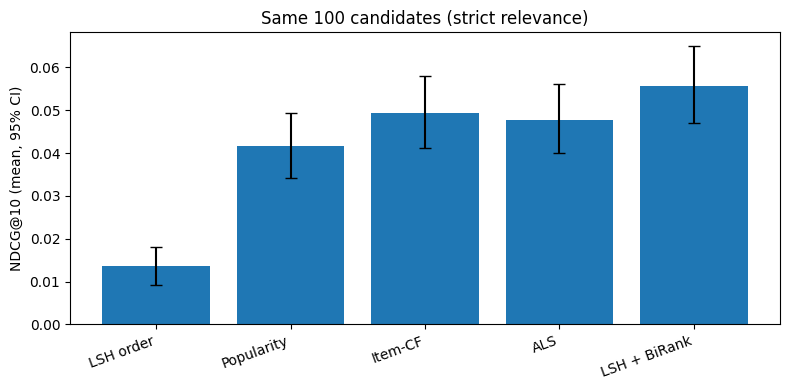

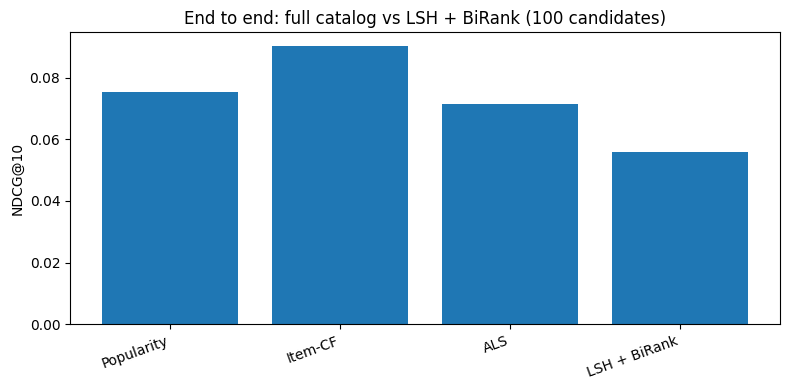

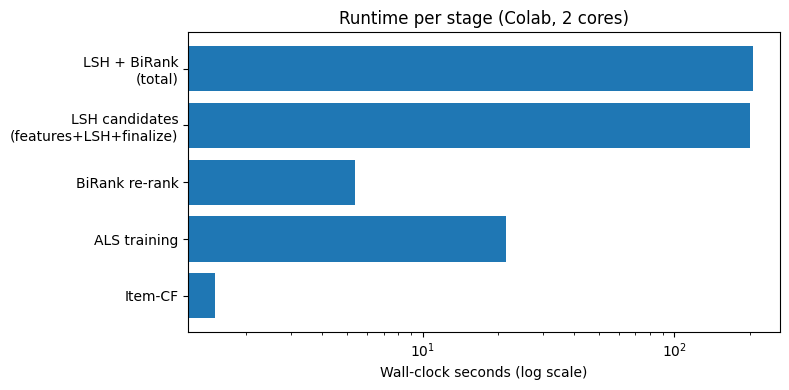

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import matplotlib.pyplot as plt
os.makedirs("results", exist_ok=True)

df = pd.DataFrame(summary).drop_duplicates(subset=["setting", "K", "method"])
s10 = df[(df.setting == "strict") & (df.K == 10)].set_index("method")

# 1) same 100 candidates, NDCG@10 with bootstrap 95% CI
same = ["LSH order", "Popularity (same candidates)", "Item-CF (same candidates)",
        "ALS (same candidates)", "LSH + BiRank"]
c = ci_table[(ci_table.K == 10) & (ci_table.metric == "ndcg")].set_index("method").loc[same]
fig, ax = plt.subplots(figsize=(8, 4))
err = [c["mean"] - c["ci95_low"], c["ci95_high"] - c["mean"]]
ax.bar(range(len(same)), c["mean"], yerr=err, capsize=4)
ax.set_xticks(range(len(same)))
ax.set_xticklabels([s.replace(" (same candidates)", "") for s in same], rotation=20, ha="right")
ax.set_ylabel("NDCG@10 (mean, 95% CI)")
ax.set_title("Same 100 candidates (strict relevance)")
plt.tight_layout()
fig.savefig("results/fig_same_candidates_ndcg10.png", dpi=150)
plt.show()

# 2) end to end, NDCG@10
full = ["Popularity (full catalog)", "Item-CF (full catalog)", "ALS (full catalog)", "LSH + BiRank"]
vals = s10.loc[full, "ndcg"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(full)), vals)
ax.set_xticks(range(len(full)))
ax.set_xticklabels([s.replace(" (full catalog)", "") for s in full], rotation=20, ha="right")
ax.set_ylabel("NDCG@10")
ax.set_title("End to end: full catalog vs LSH + BiRank (100 candidates)")
plt.tight_layout()
fig.savefig("results/fig_end_to_end_ndcg10.png", dpi=150)
plt.show()

# 3) runtime
lsh_gen = stage_times["build_features"] + stage_times["lsh_candidates"] + stage_times["finalize_candidates"]
birank_t = runtimes["BiRank re-rank, all 610 users (s)"]
rt = {"Item-CF": runtimes["Item-CF build + scoring (s)"],
      "ALS training": runtimes["ALS final training (s)"],
      "BiRank re-rank": birank_t,
      "LSH candidates\n(features+LSH+finalize)": lsh_gen,
      "LSH + BiRank\n(total)": lsh_gen + birank_t}
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(rt.keys()), list(rt.values()))
ax.set_xscale("log")
ax.set_xlabel("Wall-clock seconds (log scale)")
ax.set_title("Runtime per stage (Colab, 2 cores)")
plt.tight_layout()
fig.savefig("results/fig_runtime.png", dpi=150)
plt.show()

pd.DataFrame([runtimes]).T.to_csv("results/runtimes.csv", header=["seconds"])
!zip -qr results_with_charts.zip results
from google.colab import files
files.download("results_with_charts.zip")

In [19]:
print("Paired test, strict setting. mean_diff > 0 means LSH + BiRank is better.")
display(sig.round(4))
display(ci_table.round(4))

Paired test, strict setting. mean_diff > 0 means LSH + BiRank is better.


,K,metric,comparison,users,mean_diff,ci95_low,ci95_high,wilcoxon_p
0,10,ndcg,LSH + BiRank - LSH order,592,0.0422,0.0338,0.0508,0.0000
1,10,recall,LSH + BiRank - LSH order,592,0.0250,0.0184,0.0321,0.0000
2,20,ndcg,LSH + BiRank - LSH order,592,0.0365,0.0291,0.0445,0.0000
3,20,recall,LSH + BiRank - LSH order,592,0.0274,0.0199,0.0352,0.0000
4,10,ndcg,LSH + BiRank - Popularity (same candidates),592,0.0142,0.0098,0.0190,0.0000
5,10,recall,LSH + BiRank - Popularity (same candidates),592,0.0084,0.0058,0.0113,0.0000
6,20,ndcg,LSH + BiRank - Popularity (same candidates),592,0.0126,0.0088,0.0166,0.0000
7,20,recall,LSH + BiRank - Popularity (same candidates),592,0.0092,0.0060,0.0126,0.0000
8,10,ndcg,LSH + BiRank - Item-CF (same candidates),592,0.0065,0.0025,0.0106,0.0012
9,10,recall,LSH + BiRank - Item-CF (same candidates),592,0.0024,-0.0004,0.0051,0.0135


,method,K,metric,mean,ci95_low,ci95_high
0,LSH order,10,ndcg,0.0135,0.0093,0.0181
1,LSH order,10,recall,0.0107,0.0073,0.0146
2,LSH order,20,ndcg,0.0160,0.0119,0.0207
3,LSH order,20,recall,0.0171,0.0124,0.0224
4,Popularity (same candidates),10,ndcg,0.0416,0.0342,0.0493
5,Popularity (same candidates),10,recall,0.0273,0.0209,0.0344
6,Popularity (same candidates),20,ndcg,0.0400,0.0336,0.0466
7,Popularity (same candidates),20,recall,0.0353,0.0286,0.0427
8,Item-CF (same candidates),10,ndcg,0.0493,0.0412,0.0580
9,Item-CF (same candidates),10,recall,0.0333,0.0264,0.0409
